# Proyecto de grado — Predicción de SoH futuro en baterías EV con XGBoost

**Objetivo de este notebook:** construir de forma reproducible el primer modelo predictivo del proyecto, desde los archivos `.mat` de NASA hasta la estimación del **Estado de Salud (SoH)** actual y futuro de una batería.

Este notebook está pensado para ejecutarse en **Google Colab** y documenta no solo el código, sino también **qué se hace, para qué se hace y qué función cumple cada etapa**.

## Qué vamos a predecir

Primero construiremos un modelo base:

\[
X_t \rightarrow SoH_t
\]

Es decir: con información disponible en el ciclo actual, estimar el estado de salud actual.

Después construiremos los modelos de pronóstico:

\[
X_t \rightarrow SoH_{t+h}
\]

con horizontes:

- `h = 5` ciclos
- `h = 10` ciclos
- `h = 20` ciclos
- `h = 30` ciclos

La variable que representa directamente el **futuro estimado** será:

`soh_future_pred`

> Importante: en este notebook todavía **no calculamos RUL formalmente**. La RUL se construirá después de fijar y validar el criterio de End of Life (EOL).

## 0. Alcance del experimento piloto

Para el primer experimento trabajaremos con:

- `B0045.mat`
- `B0046.mat`
- `B0047.mat`
- `B0048.mat`

Estas cuatro baterías forman una cohorte piloto relativamente homogénea y permiten depurar correctamente el pipeline antes de mezclar condiciones experimentales más heterogéneas.

### Flujo completo

`MATLAB crudo → verificación → feature engineering → limpieza → SoH → validación por batería → XGBoost → pronóstico +5/+10/+20/+30 → métricas y archivos de resultados`

## 1. Preparar Google Colab

Sube los archivos `B0045.mat`, `B0046.mat`, `B0047.mat` y `B0048.mat` directamente al panel **Archivos** de Colab.

Cuando se suben allí, normalmente quedan en:

`/content/`

Los archivos cargados en `/content` son temporales: desaparecen cuando se reinicia la sesión. Al final incluimos una sección opcional para copiar resultados a Google Drive.

In [1]:
!pip install -q xgboost

In [2]:
# =========================================
# IMPORTACIONES
# =========================================

import os
import glob
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import scipy
import scipy.io as sio

import sklearn
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import xgboost
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("Scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)

NumPy: 2.1.3
Pandas: 2.2.3
SciPy: 1.16.3
Scikit-learn: 1.6.1
XGBoost: 3.4.1


### ¿Para qué sirve registrar las versiones?

La reproducibilidad exige saber con qué versiones se ejecutó el experimento. Dos versiones diferentes de una librería pueden producir pequeños cambios de comportamiento.

In [3]:
# =========================================
# CONFIGURACIÓN GENERAL
# =========================================

DATA_DIR = "/content"
RESULTS_DIR = "/content/resultados_xgboost"

EXPECTED_BATTERIES = [
    "B0045",
    "B0046",
    "B0047",
    "B0048"
]

WINDOW_SECONDS = 300
RANDOM_STATE = 42

os.makedirs(RESULTS_DIR, exist_ok=True)

print("Datos:", DATA_DIR)
print("Resultados:", RESULTS_DIR)

Datos: /content
Resultados: /content/resultados_xgboost


## 2. Verificación de los archivos de entrada

Antes de entrenar un modelo debemos comprobar que los archivos realmente existen. Esto evita continuar con un pipeline incompleto.

In [4]:
# Buscar únicamente las baterías piloto esperadas
mat_files = []

for battery_id in EXPECTED_BATTERIES:
    path = os.path.join(DATA_DIR, f"{battery_id}.mat")

    if os.path.exists(path):
        mat_files.append(path)
    else:
        print("FALTA:", path)

print("\nArchivos encontrados:", len(mat_files))

for path in mat_files:
    print(" -", os.path.basename(path))

assert len(mat_files) == len(EXPECTED_BATTERIES), (
    "No están disponibles las cuatro baterías piloto."
)


Archivos encontrados: 4
 - B0045.mat
 - B0046.mat
 - B0047.mat
 - B0048.mat


## 3. Carga robusta de archivos MATLAB

Los archivos `.mat` contienen estructuras MATLAB. Queremos acceder a ellas como:

- `battery.cycle`
- `cycle.type`
- `cycle.data`

La función siguiente obliga a SciPy a convertir las estructuras a una representación manejable desde Python y además corrige el caso en que quede un `numpy.ndarray` de un único elemento.

In [5]:
def load_battery_mat(file_path):
    """
    Carga una batería NASA desde un .mat y devuelve
    la estructura MATLAB principal.
    """

    battery_id = os.path.splitext(
        os.path.basename(file_path)
    )[0]

    mat = sio.loadmat(
        file_path,
        squeeze_me=True,
        struct_as_record=False
    )

    if battery_id not in mat:
        raise KeyError(
            f"No existe la variable {battery_id} dentro de {file_path}"
        )

    battery = mat[battery_id]

    # Protección adicional: desenvolver arrays de un único elemento
    while isinstance(battery, np.ndarray) and battery.size == 1:
        battery = battery.item()

    if not hasattr(battery, "_fieldnames"):
        raise TypeError(
            f"{battery_id} no se cargó como estructura MATLAB."
        )

    return battery

In [6]:
# Probar la función con B0045
example_path = os.path.join(DATA_DIR, "B0045.mat")

battery = load_battery_mat(example_path)

print("Tipo:", type(battery))
print("Campos:", battery._fieldnames)

Tipo: <class 'scipy.io.matlab._mio5_params.mat_struct'>
Campos: ['cycle']


### Resultado esperado

Debe aparecer un campo similar a:

`['cycle']`

Eso significa que ya podemos recorrer cronológicamente las operaciones de la batería.

In [7]:
cycles = np.atleast_1d(battery.cycle)

print("Número total de operaciones:", len(cycles))

for i, cycle in enumerate(cycles[:15]):
    print(
        i,
        cycle.type,
        cycle.ambient_temperature
    )

Número total de operaciones: 184
0 discharge 4
1 impedance 24
2 charge 4
3 impedance 24
4 discharge 4
5 charge 4
6 discharge 4
7 charge 4
8 discharge 4
9 charge 4
10 discharge 4
11 charge 4
12 discharge 4
13 impedance 24
14 charge 4


## 4. Identificar tipos de operación

El archivo contiene operaciones de:

- **charge**: carga
- **discharge**: descarga
- **impedance**: espectroscopia de impedancia (EIS)

Nuestro dataset tabular utilizará **una fila por descarga**. La descarga es importante porque allí existe el campo `Capacity`, que utilizaremos exclusivamente para construir la etiqueta SoH.

In [8]:
from collections import Counter

def normalize_cycle_type(value):
    if isinstance(value, bytes):
        value = value.decode("utf-8", errors="ignore")

    return str(value).strip().lower()

operation_counts = Counter(
    normalize_cycle_type(cycle.type)
    for cycle in cycles
)

print(operation_counts)

Counter({'discharge': 72, 'charge': 72, 'impedance': 40})


## 5. Inspeccionar una descarga real

Antes de automatizar el procesamiento conviene verificar manualmente la estructura de una descarga.

In [9]:
first_discharge = None

for cycle in cycles:
    if normalize_cycle_type(cycle.type) == "discharge":
        first_discharge = cycle
        break

assert first_discharge is not None, "No se encontró ninguna descarga."

print(first_discharge.data._fieldnames)

['Voltage_measured', 'Current_measured', 'Temperature_measured', 'Current_load', 'Voltage_load', 'Time', 'Capacity']


In [10]:
data = first_discharge.data

voltage = np.asarray(
    data.Voltage_measured,
    dtype=float
).ravel()

current = np.asarray(
    data.Current_measured,
    dtype=float
).ravel()

temperature = np.asarray(
    data.Temperature_measured,
    dtype=float
).ravel()

time = np.asarray(
    data.Time,
    dtype=float
).ravel()

capacity = float(
    np.asarray(data.Capacity).squeeze()
)

print("Muestras de voltaje:", len(voltage))
print("Muestras de corriente:", len(current))
print("Muestras de temperatura:", len(temperature))
print("Muestras de tiempo:", len(time))
print("Capacity:", capacity, "Ah")

Muestras de voltaje: 490
Muestras de corriente: 490
Muestras de temperatura: 490
Muestras de tiempo: 490
Capacity: 1.0819793880779518 Ah


### ¿Qué significa esto?

Una única descarga contiene cientos de mediciones. XGBoost trabaja mejor con una tabla de características fijas, así que convertiremos cada señal temporal en indicadores estadísticos.

Además, para reducir el riesgo de usar información demasiado cercana a la capacidad total, usaremos únicamente los **primeros 300 segundos** de la descarga.

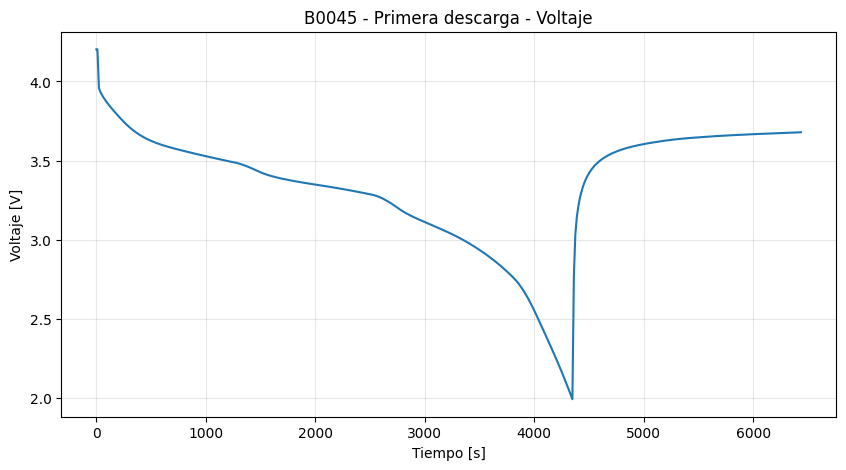

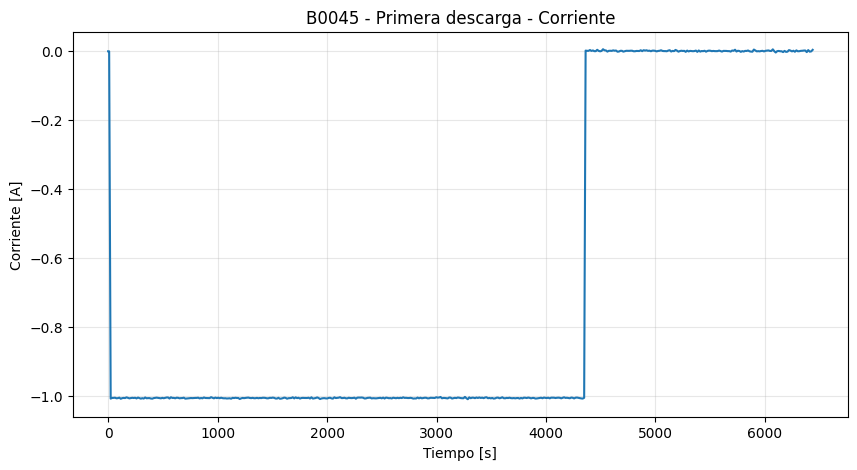

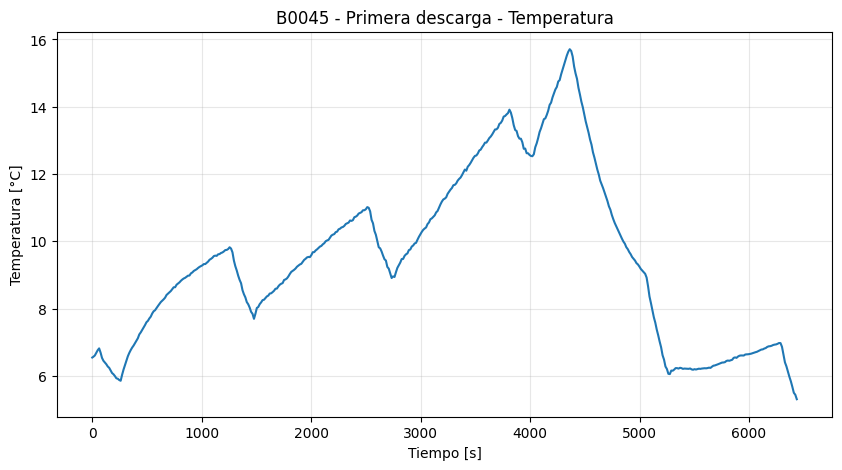

In [11]:
# Visualización de la primera descarga completa
plt.figure(figsize=(10, 5))
plt.plot(time, voltage)
plt.xlabel("Tiempo [s]")
plt.ylabel("Voltaje [V]")
plt.title("B0045 - Primera descarga - Voltaje")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(time, current)
plt.xlabel("Tiempo [s]")
plt.ylabel("Corriente [A]")
plt.title("B0045 - Primera descarga - Corriente")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(time, temperature)
plt.xlabel("Tiempo [s]")
plt.ylabel("Temperatura [°C]")
plt.title("B0045 - Primera descarga - Temperatura")
plt.grid(alpha=0.3)
plt.show()

### Cómo leer estas gráficas

- **Voltaje vs tiempo:** muestra cómo cae el voltaje durante la descarga.
- **Corriente vs tiempo:** permite comprobar el perfil de corriente aplicado.
- **Temperatura vs tiempo:** muestra el calentamiento de la celda durante la operación.

Estas gráficas se utilizan inicialmente como control de calidad y para entender las señales originales.

## 6. Funciones auxiliares de preprocesamiento

In [12]:
def safe_array(value):
    """Convierte un valor MATLAB en vector NumPy float."""
    try:
        return np.asarray(value, dtype=float).ravel()
    except Exception:
        return np.array([], dtype=float)


def safe_scalar(value):
    """Convierte un valor MATLAB escalar en float."""
    try:
        arr = np.asarray(value).squeeze()

        if arr.size == 1:
            return float(arr)

        return np.nan

    except Exception:
        return np.nan

In [13]:
def get_time_window(time, signal, max_seconds=300):
    """
    Conserva únicamente los valores válidos de una señal
    comprendidos entre el inicio y max_seconds.
    """

    time = safe_array(time)
    signal = safe_array(signal)

    n = min(len(time), len(signal))

    time = time[:n]
    signal = signal[:n]

    mask = (
        np.isfinite(time)
        &
        np.isfinite(signal)
        &
        (time <= max_seconds)
    )

    return time[mask], signal[mask]


def summarize_window(time, signal, prefix, max_seconds=300):
    """
    Resume una señal temporal en características numéricas
    de longitud fija.
    """

    t, x = get_time_window(
        time,
        signal,
        max_seconds
    )

    if len(x) == 0:
        return {
            f"{prefix}_start": np.nan,
            f"{prefix}_mean": np.nan,
            f"{prefix}_std": np.nan,
            f"{prefix}_min": np.nan,
            f"{prefix}_max": np.nan,
            f"{prefix}_end": np.nan,
            f"{prefix}_delta": np.nan,
            f"{prefix}_n_samples": 0
        }

    return {
        f"{prefix}_start": x[0],
        f"{prefix}_mean": np.mean(x),
        f"{prefix}_std": np.std(x),
        f"{prefix}_min": np.min(x),
        f"{prefix}_max": np.max(x),
        f"{prefix}_end": x[-1],
        f"{prefix}_delta": x[-1] - x[0],
        f"{prefix}_n_samples": len(x)
    }

### ¿Qué función cumple `summarize_window`?

Convierte, por ejemplo, cientos de voltajes en:

- voltaje inicial
- voltaje medio
- desviación estándar
- mínimo
- máximo
- voltaje al final de la ventana
- cambio de voltaje

El mismo procedimiento se aplica a corriente y temperatura.

Esto es **feature engineering**: transformar señales crudas en variables útiles para Machine Learning.

## 7. Condiciones experimentales conocidas

El voltaje de corte cambia entre las cuatro baterías, por lo que se conserva como característica del protocolo.

In [14]:
CUTOFF_MAP = {
    "B0045": 2.0,
    "B0046": 2.2,
    "B0047": 2.5,
    "B0048": 2.7
}

## 8. Construir una fila por descarga

La siguiente función recorre cada batería cronológicamente.

Reglas importantes:

1. **Una descarga = una fila**.
2. Solo se usan los primeros `300 s` de voltaje, corriente y temperatura.
3. Se utiliza únicamente el **último EIS conocido antes de la descarga**, evitando información futura.
4. `Capacity` se conserva únicamente para construir SoH y **no se utilizará como variable X**.
5. Los valores EIS claramente absurdos se convierten en `NaN` en lugar de cero.

In [15]:
def extract_battery_features(
    file_path,
    window_seconds=300
):
    battery_id = os.path.splitext(
        os.path.basename(file_path)
    )[0]

    battery = load_battery_mat(file_path)

    cycles = np.atleast_1d(
        battery.cycle
    )

    rows = []
    discharge_number = 0

    last_eis = {
        "Re_prev": np.nan,
        "Rct_prev": np.nan
    }

    last_charge = {
        "charge_duration_prev": np.nan,
        "charge_temp_start_prev": np.nan,
        "charge_temp_max_prev": np.nan,
        "charge_temp_delta_prev": np.nan
    }

    for cycle in cycles:

        cycle_type = normalize_cycle_type(
            cycle.type
        )

        # -------------------------------------
        # IMPEDANCIA
        # -------------------------------------
        if cycle_type == "impedance":

            Re = safe_scalar(
                cycle.data.Re
            )

            Rct = safe_scalar(
                cycle.data.Rct
            )

            # Guardrails de calidad amplios
            if not (
                np.isfinite(Re)
                and 0 < Re < 1
            ):
                Re = np.nan

            if not (
                np.isfinite(Rct)
                and 0 < Rct < 2
            ):
                Rct = np.nan

            last_eis = {
                "Re_prev": Re,
                "Rct_prev": Rct
            }

        # -------------------------------------
        # CARGA
        # -------------------------------------
        elif cycle_type == "charge":

            data = cycle.data

            charge_time = safe_array(
                data.Time
            )

            charge_temperature = safe_array(
                data.Temperature_measured
            )

            if len(charge_time) > 0:
                charge_duration = (
                    charge_time[-1]
                    - charge_time[0]
                )
            else:
                charge_duration = np.nan

            valid_temp = charge_temperature[
                np.isfinite(
                    charge_temperature
                )
            ]

            if len(valid_temp) > 0:
                charge_temp_start = valid_temp[0]
                charge_temp_max = np.max(valid_temp)
                charge_temp_delta = (
                    valid_temp[-1]
                    - valid_temp[0]
                )
            else:
                charge_temp_start = np.nan
                charge_temp_max = np.nan
                charge_temp_delta = np.nan

            last_charge = {
                "charge_duration_prev":
                    charge_duration,

                "charge_temp_start_prev":
                    charge_temp_start,

                "charge_temp_max_prev":
                    charge_temp_max,

                "charge_temp_delta_prev":
                    charge_temp_delta
            }

        # -------------------------------------
        # DESCARGA
        # -------------------------------------
        elif cycle_type == "discharge":

            discharge_number += 1

            data = cycle.data

            time = safe_array(
                data.Time
            )

            voltage = safe_array(
                data.Voltage_measured
            )

            current = safe_array(
                data.Current_measured
            )

            temperature = safe_array(
                data.Temperature_measured
            )

            row = {
                "battery_id":
                    battery_id,

                "cycle":
                    discharge_number,

                "ambient_temperature":
                    safe_scalar(
                        cycle.ambient_temperature
                    ),

                "cutoff_voltage":
                    CUTOFF_MAP.get(
                        battery_id,
                        np.nan
                    ),

                # SOLO target auxiliar.
                "capacity":
                    safe_scalar(
                        data.Capacity
                    )
            }

            row.update(
                summarize_window(
                    time,
                    voltage,
                    "voltage",
                    window_seconds
                )
            )

            row.update(
                summarize_window(
                    time,
                    current,
                    "current",
                    window_seconds
                )
            )

            row.update(
                summarize_window(
                    time,
                    temperature,
                    "temperature",
                    window_seconds
                )
            )

            row.update(last_eis)
            row.update(last_charge)

            rows.append(row)

    return pd.DataFrame(rows)

## 9. Probar la extracción en una sola batería

In [16]:
b0045_df = extract_battery_features(
    "/content/B0045.mat",
    window_seconds=WINDOW_SECONDS
)

print("Dimensión B0045:", b0045_df.shape)
display(b0045_df.head())

Dimensión B0045: (72, 35)


,battery_id,cycle,ambient_temperature,cutoff_voltage,capacity,voltage_start,voltage_mean,voltage_std,voltage_min,voltage_max,...,temperature_max,temperature_end,temperature_delta,temperature_n_samples,Re_prev,Rct_prev,charge_duration_prev,charge_temp_start_prev,charge_temp_max_prev,charge_temp_delta_prev
0,B0045,1,4.0,2.0,1.081979,4.202937,3.850271,0.126130,3.712434,4.203468,...,6.817809,6.319312,-0.226817,24,NaN,NaN,NaN,NaN,NaN,NaN
1,B0045,2,4.0,2.0,0.927952,4.166901,3.848406,0.114404,3.732075,4.166999,...,7.372047,7.372047,1.710315,23,0.065087,0.21441,10803.313,6.201578,8.785650,-0.250374
2,B0045,3,4.0,2.0,0.885194,4.187653,3.866291,0.118725,3.735409,4.187894,...,6.599710,6.008551,-0.413437,23,0.065087,0.21441,10802.078,5.464715,8.853130,0.808182
3,B0045,4,4.0,2.0,0.858101,4.188401,3.853296,0.121649,3.727323,4.188401,...,6.596915,6.596915,1.819090,23,0.065087,0.21441,10807.688,4.846613,8.776292,-0.264836
4,B0045,5,4.0,2.0,0.840935,4.188304,3.852403,0.122061,3.726080,4.188304,...,6.878112,6.878112,1.830838,23,0.065087,0.21441,10805.687,5.228954,8.775347,-0.306057


In [17]:
print("Descargas sin voltaje:",
      (b0045_df["voltage_n_samples"] == 0).sum())

print("Descargas sin corriente:",
      (b0045_df["current_n_samples"] == 0).sum())

print("Descargas sin temperatura:",
      (b0045_df["temperature_n_samples"] == 0).sum())

Descargas sin voltaje: 0
Descargas sin corriente: 0
Descargas sin temperatura: 0


Si aparecen muchas descargas con `0` muestras, hay que detenerse y revisar la extracción. Si todo es razonable, procesamos las cuatro baterías.

## 10. Procesar las cuatro baterías

In [18]:
battery_dfs = []

for file_path in mat_files:

    battery_id = os.path.splitext(
        os.path.basename(file_path)
    )[0]

    print("Procesando:", battery_id)

    battery_df = extract_battery_features(
        file_path,
        window_seconds=WINDOW_SECONDS
    )

    print("Descargas:", len(battery_df))

    battery_dfs.append(
        battery_df
    )

df = pd.concat(
    battery_dfs,
    ignore_index=True
)

print("\nDimensión final:", df.shape)

display(
    df.groupby("battery_id").size()
)

Procesando: B0045
Descargas: 72
Procesando: B0046
Descargas: 72
Procesando: B0047
Descargas: 72
Procesando: B0048
Descargas: 72

Dimensión final: (288, 35)


,0
battery_id,
B0045,72
B0046,72
B0047,72
B0048,72


## 11. Auditoría de calidad

Antes de construir el target verificamos:

- tipos de datos
- missing values
- duplicados
- capacidades inválidas
- distribuciones físicas

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 288 entries, 0 to 287
Data columns (total 35 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   battery_id              288 non-null    object 
 1   cycle                   288 non-null    int64  
 2   ambient_temperature     288 non-null    float64
 3   cutoff_voltage          288 non-null    float64
 4   capacity                288 non-null    float64
 5   voltage_start           288 non-null    float64
 6   voltage_mean            288 non-null    float64
 7   voltage_std             288 non-null    float64
 8   voltage_min             288 non-null    float64
 9   voltage_max             288 non-null    float64
 10  voltage_end             288 non-null    float64
 11  voltage_delta           288 non-null    float64
 12  voltage_n_samples       288 non-null    int64  
 13  current_start           288 non-null    float64
 14  current_mean            288 non-null    fl

In [20]:
missing_report = pd.DataFrame({
    "missing_count":
        df.isna().sum(),

    "missing_percent":
        df.isna().mean() * 100
}).sort_values(
    "missing_percent",
    ascending=False
)

display(missing_report)

,missing_count,missing_percent
Rct_prev,4,1.388889
charge_temp_delta_prev,4,1.388889
charge_temp_max_prev,4,1.388889
charge_temp_start_prev,4,1.388889
charge_duration_prev,4,1.388889
Re_prev,4,1.388889
battery_id,0,0.000000
ambient_temperature,0,0.000000
cycle,0,0.000000
cutoff_voltage,0,0.000000


In [21]:
print(
    "Filas completamente duplicadas:",
    df.duplicated().sum()
)

print(
    "Batería-ciclo duplicados:",
    df.duplicated(
        subset=[
            "battery_id",
            "cycle"
        ]
    ).sum()
)

Filas completamente duplicadas: 0
Batería-ciclo duplicados: 0


In [22]:
display(
    df.describe().T
)

,count,mean,std,min,25%,50%,75%,max
cycle,288.0,36.500000,20.818780,1.000000,18.750000,36.500000,54.250000,72.000000
ambient_temperature,288.0,4.000000,0.000000,4.000000,4.000000,4.000000,4.000000,4.000000
cutoff_voltage,288.0,2.350000,0.269727,2.000000,2.150000,2.350000,2.550000,2.700000
capacity,288.0,1.091763,0.344139,0.000000,0.797143,1.202173,1.297594,1.728239
voltage_start,288.0,4.174238,0.022320,4.086998,4.169459,4.174641,4.189384,4.246711
voltage_mean,288.0,3.867532,0.040662,3.698991,3.843693,3.873857,3.893970,3.964430
voltage_std,288.0,0.112117,0.015898,0.084436,0.100290,0.109234,0.118744,0.149189
voltage_min,288.0,3.760478,0.060668,3.545704,3.727012,3.773449,3.797290,3.876256
voltage_max,288.0,4.174264,0.022292,4.087129,4.169459,4.174641,4.189384,4.246764
voltage_end,288.0,3.760478,0.060668,3.545704,3.727012,3.773449,3.797290,3.876256


### Importante sobre valores faltantes

No todos los `NaN` son errores. Por ejemplo, `Re_prev = NaN` puede significar que todavía no existía una medición EIS previa.

Por eso **no** hacemos un `dropna()` general.

## 12. Revisar la capacidad

`Capacity` es la base para calcular el SoH real, por lo que debemos inspeccionarla antes de construir el target.

In [23]:
capacity_summary = (
    df
    .groupby("battery_id")
    ["capacity"]
    .agg([
        "count",
        "min",
        "max",
        "mean",
        "median",
        "std"
    ])
)

display(capacity_summary)

,count,min,max,mean,median,std
battery_id,,,,,,
B0045,72,0.0,1.081979,0.688886,0.687754,0.143672
B0046,72,0.0,1.728239,1.229230,1.244954,0.285828
B0047,72,0.0,1.674305,1.203566,1.205225,0.279584
B0048,72,0.0,1.657996,1.245371,1.261287,0.279036


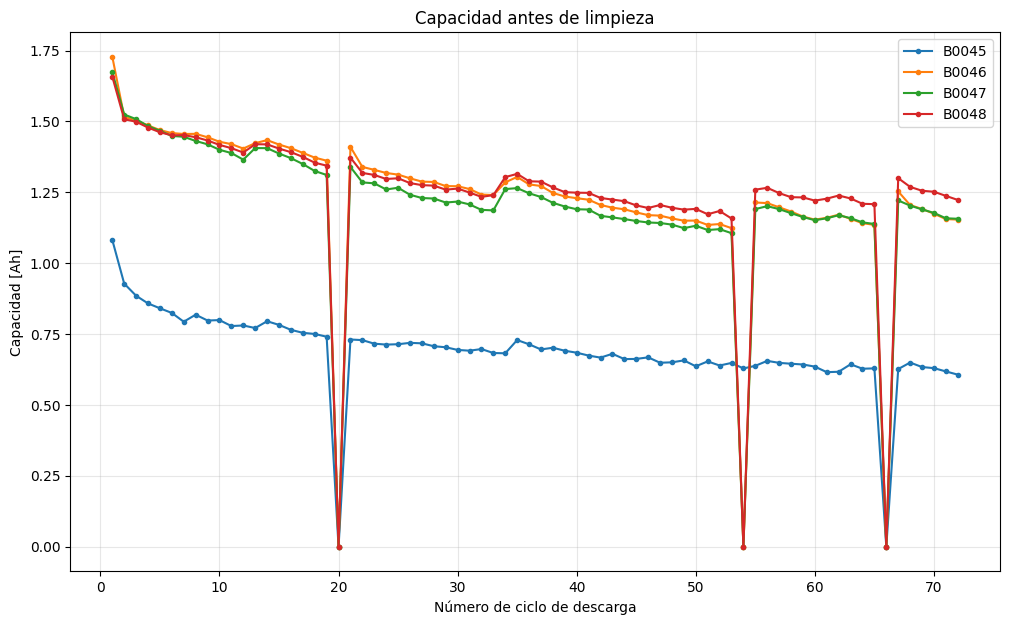

In [24]:
plt.figure(figsize=(12, 7))

for battery_id, group in df.groupby(
    "battery_id"
):
    group = group.sort_values(
        "cycle"
    )

    plt.plot(
        group["cycle"],
        group["capacity"],
        marker=".",
        label=battery_id
    )

plt.xlabel("Número de ciclo de descarga")
plt.ylabel("Capacidad [Ah]")
plt.title("Capacidad antes de limpieza")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Cómo leer esta gráfica

- Eje X: número de descarga.
- Eje Y: capacidad observada en Ah.
- Una tendencia descendente gradual es consistente con degradación.
- Un valor aislado igual a `0` entre capacidades normales es sospechoso y se marca como inválido.

In [25]:
df["flag_capacity_missing"] = (
    df["capacity"].isna()
)

df["flag_capacity_nonpositive"] = (
    df["capacity"] <= 0
)

df["flag_capacity_invalid"] = (
    df["flag_capacity_missing"]
    |
    df["flag_capacity_nonpositive"]
)

quality_summary = (
    df
    .groupby("battery_id")
    ["flag_capacity_invalid"]
    .agg([
        "count",
        "sum"
    ])
)

quality_summary.columns = [
    "total_cycles",
    "invalid_cycles"
]

display(quality_summary)

,total_cycles,invalid_cycles
battery_id,,
B0045,72,2
B0046,72,3
B0047,72,3
B0048,72,3


In [26]:
df_clean = df[
    ~df[
        "flag_capacity_invalid"
    ]
].copy()

print("Observaciones originales:", len(df))
print("Observaciones válidas:", len(df_clean))
print("Eliminadas:", len(df) - len(df_clean))

Observaciones originales: 288
Observaciones válidas: 277
Eliminadas: 11


## 13. Construcción del SoH

Definimos una capacidad de referencia por batería:

\[
Q_{ref} = mediana(Q_1,\ldots,Q_5)
\]

utilizando las primeras cinco capacidades válidas.

Después:

\[
SoH_t = rac{Q_t}{Q_{ref}}	imes100
\]

La mediana reduce la sensibilidad a un primer ciclo anómalo.

In [27]:
q_ref_table = (
    df_clean
    .sort_values([
        "battery_id",
        "cycle"
    ])
    .groupby(
        "battery_id"
    )
    .head(5)
    .groupby(
        "battery_id"
    )
    ["capacity"]
    .median()
)

display(q_ref_table)

,capacity
battery_id,
B0045,0.885194
B0046,1.503121
B0047,1.508076
B0048,1.498922


In [28]:
df_clean["q_ref"] = (
    df_clean[
        "battery_id"
    ]
    .map(q_ref_table)
)

df_clean["soh"] = (
    df_clean["capacity"]
    /
    df_clean["q_ref"]
) * 100

display(
    df_clean[
        [
            "battery_id",
            "cycle",
            "capacity",
            "q_ref",
            "soh"
        ]
    ].head(20)
)

,battery_id,cycle,capacity,q_ref,soh
0,B0045,1,1.081979,0.885194,122.230818
1,B0045,2,0.927952,0.885194,104.830446
2,B0045,3,0.885194,0.885194,100.000000
3,B0045,4,0.858101,0.885194,96.939366
4,B0045,5,0.840935,0.885194,95.000146
5,B0045,6,0.824547,0.885194,93.148797
6,B0045,7,0.793596,0.885194,89.652256
7,B0045,8,0.818368,0.885194,92.450691
8,B0045,9,0.797764,0.885194,90.123157
9,B0045,10,0.799378,0.885194,90.305413


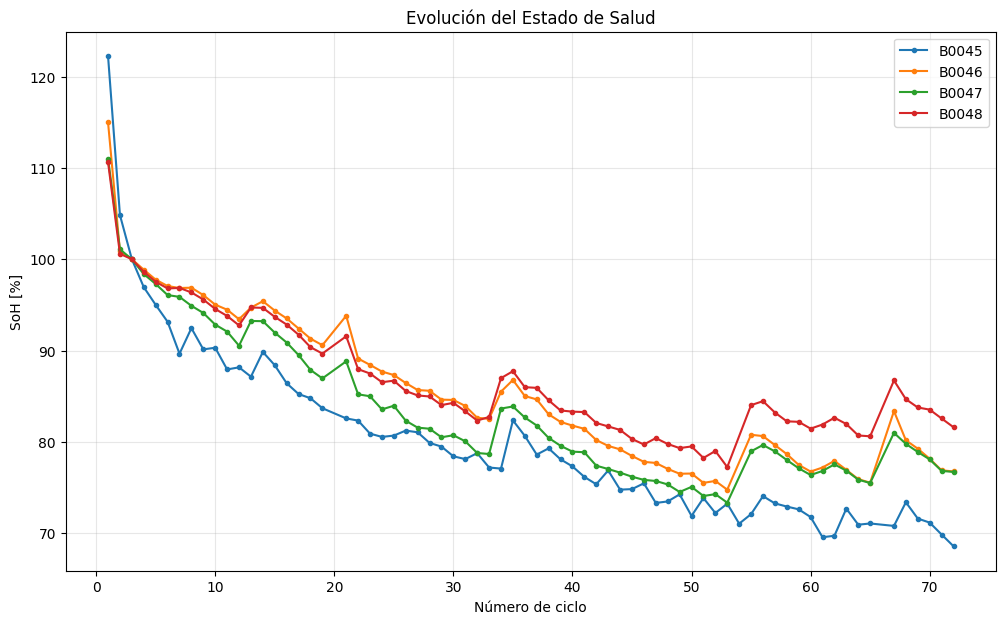

In [29]:
plt.figure(figsize=(12, 7))

for battery_id, group in (
    df_clean
    .groupby("battery_id")
):
    group = group.sort_values(
        "cycle"
    )

    plt.plot(
        group["cycle"],
        group["soh"],
        marker=".",
        label=battery_id
    )

plt.xlabel("Número de ciclo")
plt.ylabel("SoH [%]")
plt.title("Evolución del Estado de Salud")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Cómo leer la gráfica de SoH

- Cerca de `100 %`: capacidad similar a la referencia inicial.
- Valores menores: pérdida progresiva de capacidad respecto al inicio.
- Pequeñas recuperaciones locales pueden deberse a variabilidad experimental y no necesariamente a una recuperación física real.

No se recorta artificialmente el SoH a `100 %`.

In [30]:
# Guardar dataset procesado
PROCESSED_FILE = os.path.join(
    RESULTS_DIR,
    "B0045_B0048_clean_SoH.csv"
)

df_clean.to_csv(
    PROCESSED_FILE,
    index=False
)

print(PROCESSED_FILE)

/content/resultados_xgboost/B0045_B0048_clean_SoH.csv


## 14. Definir las variables predictoras X

### Variables que NO entran a X

- `capacity`: forma parte del cálculo del target.
- `q_ref`: forma parte del cálculo del target.
- `soh`: es la respuesta que queremos predecir.
- `battery_id`: es un identificador, no una característica física.

Incluir esas variables produciría **data leakage**.

También dejamos fuera `charge_duration_prev` en el baseline para reducir el riesgo de utilizar un proxy excesivamente cercano a la capacidad aceptada durante la carga.

In [31]:
FEATURES = [

    # Edad operacional
    "cycle",

    # Condiciones experimentales
    "ambient_temperature",
    "cutoff_voltage",

    # Voltaje primeros 300 s
    "voltage_start",
    "voltage_mean",
    "voltage_std",
    "voltage_min",
    "voltage_max",
    "voltage_end",
    "voltage_delta",

    # Corriente primeros 300 s
    "current_start",
    "current_mean",
    "current_std",
    "current_min",
    "current_max",
    "current_end",
    "current_delta",

    # Temperatura primeros 300 s
    "temperature_start",
    "temperature_mean",
    "temperature_std",
    "temperature_min",
    "temperature_max",
    "temperature_end",
    "temperature_delta",

    # EIS previo
    "Re_prev",
    "Rct_prev",

    # Temperatura de carga previa
    "charge_temp_start_prev",
    "charge_temp_max_prev",
    "charge_temp_delta_prev"
]

TARGET = "soh"

X = df_clean[
    FEATURES
].copy()

y = df_clean[
    TARGET
].copy()

groups = df_clean[
    "battery_id"
].copy()

print("X:", X.shape)
print("y:", y.shape)
print("groups:", groups.shape)

forbidden = [
    "capacity",
    "q_ref",
    "soh",
    "battery_id"
]

print("\nChequeo de leakage:")
for item in forbidden:
    print(item, "en X:", item in X.columns)

X: (277, 29)
y: (277,)
groups: (277,)

Chequeo de leakage:
capacity en X: False
q_ref en X: False
soh en X: False
battery_id en X: False


## 15. Baseline: predecir el SoH actual

Antes de pronosticar el futuro comprobamos si XGBoost puede estimar correctamente el estado actual.

La validación utilizada será **Leave-One-Battery-Out**:

- se entrena con tres baterías;
- se prueba con la cuarta;
- se repite hasta probar las cuatro.

Esto evita evaluar el modelo con ciclos de una batería que ya vio durante el entrenamiento.

In [32]:
def evaluate_current_soh_xgboost(
    dataframe,
    features
):
    X_local = dataframe[
        features
    ].copy()

    y_local = dataframe[
        "soh"
    ].copy()

    groups_local = dataframe[
        "battery_id"
    ].copy()

    logo = LeaveOneGroupOut()

    metrics = []
    predictions = []
    models = {}

    for fold, (
        train_idx,
        test_idx
    ) in enumerate(
        logo.split(
            X_local,
            y_local,
            groups_local
        ),
        start=1
    ):

        X_train = X_local.iloc[
            train_idx
        ]

        X_test = X_local.iloc[
            test_idx
        ]

        y_train = y_local.iloc[
            train_idx
        ]

        y_test = y_local.iloc[
            test_idx
        ]

        test_groups = groups_local.iloc[
            test_idx
        ]

        test_battery = (
            test_groups
            .unique()[0]
        )

        model = XGBRegressor(
            n_estimators=500,
            learning_rate=0.03,
            max_depth=4,
            min_child_weight=3,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_alpha=0.0,
            reg_lambda=1.0,
            objective="reg:squarederror",
            random_state=RANDOM_STATE,
            n_jobs=-1
        )

        model.fit(
            X_train,
            y_train
        )

        y_pred = model.predict(
            X_test
        )

        mae = mean_absolute_error(
            y_test,
            y_pred
        )

        rmse = np.sqrt(
            mean_squared_error(
                y_test,
                y_pred
            )
        )

        r2 = r2_score(
            y_test,
            y_pred
        )

        metrics.append({
            "horizon": 0,
            "fold": fold,
            "test_battery": test_battery,
            "n_train": len(X_train),
            "n_test": len(X_test),
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

        pred_df = pd.DataFrame({
            "battery_id":
                test_groups.values,

            "cycle":
                dataframe.iloc[
                    test_idx
                ]["cycle"].values,

            "soh_real":
                y_test.values,

            "soh_pred":
                y_pred
        })

        predictions.append(
            pred_df
        )

        models[
            test_battery
        ] = model

    return (
        pd.DataFrame(metrics),
        pd.concat(
            predictions,
            ignore_index=True
        ),
        models
    )

In [33]:
metrics_0, predictions_0, models_0 = (
    evaluate_current_soh_xgboost(
        df_clean,
        FEATURES
    )
)

display(metrics_0.round(4))

,horizon,fold,test_battery,n_train,n_test,MAE,RMSE,R2
0,0,1,B0045,207,70,2.7261,3.6305,0.8522
1,0,2,B0046,208,69,1.4225,1.8713,0.9490
2,0,3,B0047,208,69,3.6210,3.9969,0.7531
3,0,4,B0048,208,69,3.2075,3.4281,0.7293


### Interpretación de métricas

**MAE:** error absoluto promedio en puntos porcentuales de SoH.  
Ejemplo: `MAE = 2.5` significa que el modelo se desvía aproximadamente `2.5 puntos porcentuales` del SoH real.

**RMSE:** también mide error, pero penaliza más los errores grandes.

**R²:** mide capacidad explicativa. Un valor cercano a 1 es mejor. Un R² negativo significa que para esa batería el modelo generalizó muy mal; no significa automáticamente que el código esté roto.

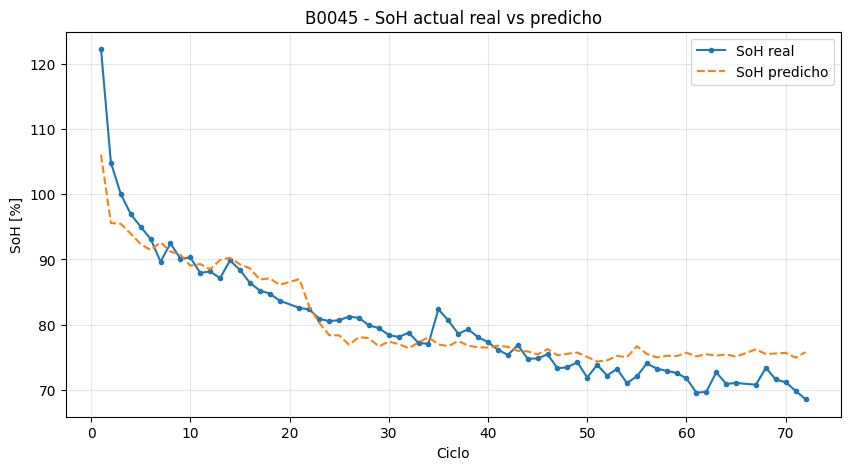

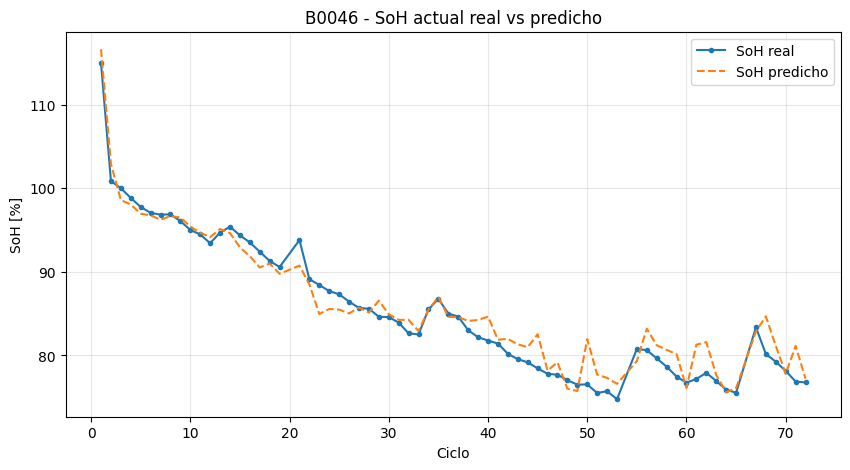

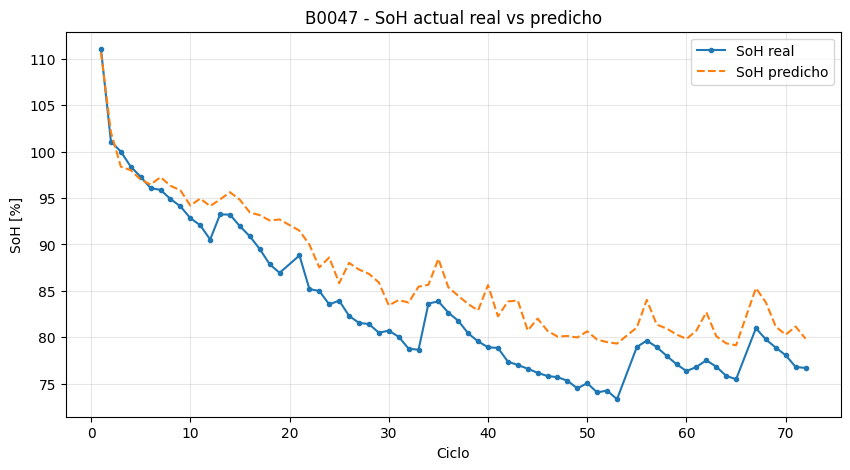

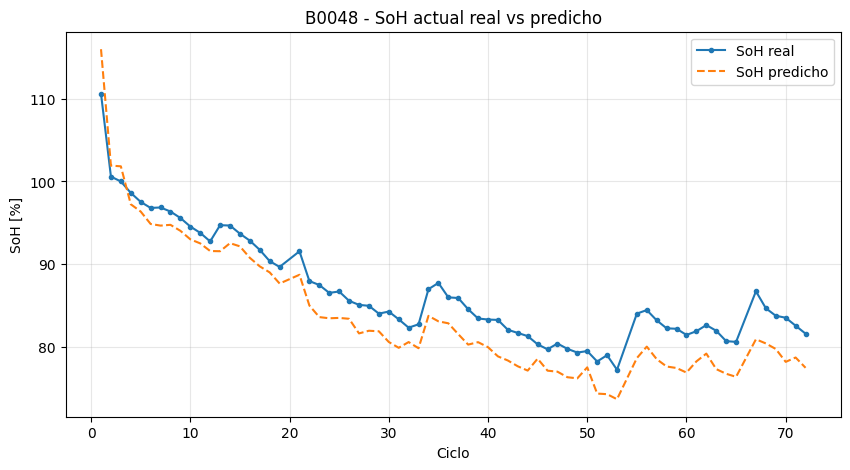

In [34]:
# Gráficas por batería: SoH actual real vs predicho
for battery_id, group in (
    predictions_0
    .groupby("battery_id")
):
    group = group.sort_values(
        "cycle"
    )

    plt.figure(figsize=(10, 5))

    plt.plot(
        group["cycle"],
        group["soh_real"],
        marker=".",
        label="SoH real"
    )

    plt.plot(
        group["cycle"],
        group["soh_pred"],
        linestyle="--",
        label="SoH predicho"
    )

    plt.xlabel("Ciclo")
    plt.ylabel("SoH [%]")
    plt.title(
        f"{battery_id} - SoH actual real vs predicho"
    )
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

## 16. Primer pronóstico futuro: construir el target \(SoH_{t+h}\)

No usamos simplemente `shift(-h)` porque después de la limpieza puede faltar algún número de ciclo.

En su lugar hacemos una alineación explícita por:

- `battery_id`
- `cycle`

Así garantizamos que:

`ciclo 20 → target ciclo 30`

sea realmente un horizonte de `+10 ciclos`.

In [35]:
def create_future_dataset(
    dataframe,
    horizon
):
    """
    Relaciona las características del ciclo t con
    el SoH observado exactamente horizon ciclos después.
    """

    target_table = dataframe[
        [
            "battery_id",
            "cycle",
            "soh"
        ]
    ].copy()

    # Mover el target futuro al ciclo actual
    target_table[
        "cycle"
    ] = (
        target_table[
            "cycle"
        ]
        -
        horizon
    )

    target_name = (
        f"soh_future_{horizon}"
    )

    target_table = (
        target_table
        .rename(
            columns={
                "soh":
                    target_name
            }
        )
    )

    future_df = dataframe.merge(
        target_table,

        on=[
            "battery_id",
            "cycle"
        ],

        how="left"
    )

    # Solo se conservan ejemplos cuyo futuro
    # fue realmente observado.
    future_df = future_df[
        future_df[
            target_name
        ].notna()
    ].copy()

    return (
        future_df,
        target_name
    )

## 17. Función de entrenamiento para cualquier horizonte futuro

In [36]:
def evaluate_future_xgboost(
    dataframe,
    features,
    horizon
):
    future_df, target_name = (
        create_future_dataset(
            dataframe,
            horizon
        )
    )

    X_h = future_df[
        features
    ].copy()

    y_h = future_df[
        target_name
    ].copy()

    groups_h = future_df[
        "battery_id"
    ].copy()

    logo = LeaveOneGroupOut()

    metrics = []
    predictions = []
    models = {}

    for fold, (
        train_idx,
        test_idx
    ) in enumerate(
        logo.split(
            X_h,
            y_h,
            groups_h
        ),
        start=1
    ):

        X_train = X_h.iloc[
            train_idx
        ]

        X_test = X_h.iloc[
            test_idx
        ]

        y_train = y_h.iloc[
            train_idx
        ]

        y_test = y_h.iloc[
            test_idx
        ]

        test_groups = groups_h.iloc[
            test_idx
        ]

        test_battery = (
            test_groups
            .unique()[0]
        )

        model = XGBRegressor(
            n_estimators=500,
            learning_rate=0.03,
            max_depth=4,
            min_child_weight=3,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_alpha=0.0,
            reg_lambda=1.0,
            objective="reg:squarederror",
            random_state=RANDOM_STATE,
            n_jobs=-1
        )

        model.fit(
            X_train,
            y_train
        )

        y_pred = model.predict(
            X_test
        )

        mae = mean_absolute_error(
            y_test,
            y_pred
        )

        rmse = np.sqrt(
            mean_squared_error(
                y_test,
                y_pred
            )
        )

        r2 = r2_score(
            y_test,
            y_pred
        )

        metrics.append({
            "horizon": horizon,
            "fold": fold,
            "test_battery": test_battery,
            "n_train": len(X_train),
            "n_test": len(X_test),
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

        pred_df = pd.DataFrame({
            "battery_id":
                test_groups.values,

            "current_cycle":
                future_df.iloc[
                    test_idx
                ]["cycle"].values,

            "future_cycle":
                (
                    future_df.iloc[
                        test_idx
                    ]["cycle"].values
                    +
                    horizon
                ),

            "soh_future_real":
                y_test.values,

            "soh_future_pred":
                y_pred
        })

        predictions.append(
            pred_df
        )

        models[
            test_battery
        ] = model

    return (
        pd.DataFrame(metrics),
        pd.concat(
            predictions,
            ignore_index=True
        ),
        models
    )

## 18. Ejecutar la primera predicción futura (+10 ciclos)

Esta es la primera predicción explícita de futuro:

\[
X_t
ightarrow SoH_{t+10}
\]

La columna `soh_future_pred` será el SoH futuro estimado por XGBoost.

In [37]:
metrics_10, predictions_10, models_10 = (
    evaluate_future_xgboost(
        df_clean,
        FEATURES,
        horizon=10
    )
)

display(metrics_10.round(4))
display(predictions_10.head(15))

,horizon,fold,test_battery,n_train,n_test,MAE,RMSE,R2
0,10,1,B0045,171,59,3.7181,4.1984,0.4260
1,10,2,B0046,173,57,2.4777,2.9436,0.7607
2,10,3,B0047,173,57,3.5835,3.9297,0.4525
3,10,4,B0048,173,57,4.2317,4.7076,-0.1565


,battery_id,current_cycle,future_cycle,soh_future_real,soh_future_pred
0,B0045,1,11,87.925482,90.812027
1,B0045,2,12,88.158547,89.906250
2,B0045,3,13,87.134138,89.936279
3,B0045,4,14,89.842381,89.974609
4,B0045,5,15,88.388891,89.665901
5,B0045,6,16,86.415163,89.003517
6,B0045,7,17,85.234454,88.796646
7,B0045,8,18,84.772968,88.165466
8,B0045,9,19,83.679525,87.785454
9,B0045,11,21,82.564148,87.747757


### Cómo leer `predictions_10`

Ejemplo conceptual:

| battery_id | current_cycle | future_cycle | soh_future_real | soh_future_pred |
|---|---:|---:|---:|---:|
| B0045 | 20 | 30 | 90.1 | 88.9 |

Interpretación:

> Usando información disponible en el ciclo 20, el modelo predijo que en el ciclo 30 la batería tendría un SoH de 88.9 %. Como el dataset es histórico, también conocemos el valor real (90.1 %) y podemos medir el error.

En una batería real cuyo futuro todavía no ocurrió, solo tendríamos `soh_future_pred`.

In [38]:
# Error individual +10
predictions_10["error"] = (
    predictions_10[
        "soh_future_pred"
    ]
    -
    predictions_10[
        "soh_future_real"
    ]
)

predictions_10[
    "absolute_error"
] = np.abs(
    predictions_10[
        "error"
    ]
)

display(
    predictions_10.head()
)

,battery_id,current_cycle,future_cycle,soh_future_real,soh_future_pred,error,absolute_error
0,B0045,1,11,87.925482,90.812027,2.886545,2.886545
1,B0045,2,12,88.158547,89.906250,1.747703,1.747703
2,B0045,3,13,87.134138,89.936279,2.802141,2.802141
3,B0045,4,14,89.842381,89.974609,0.132228,0.132228
4,B0045,5,15,88.388891,89.665901,1.277010,1.277010


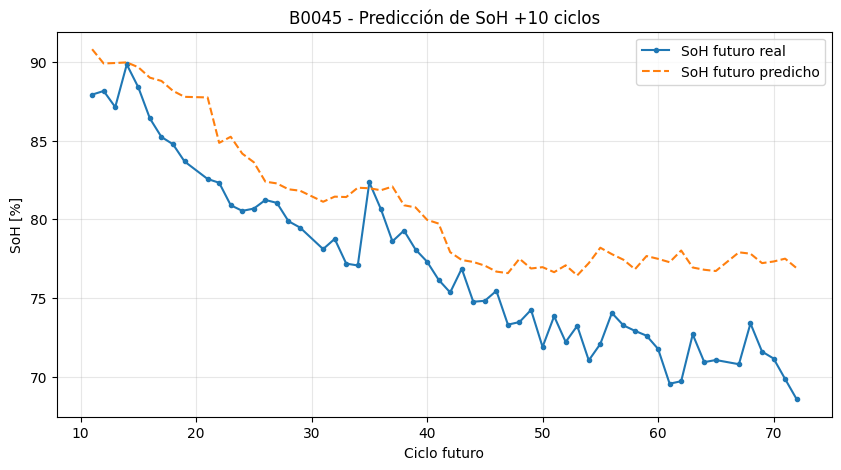

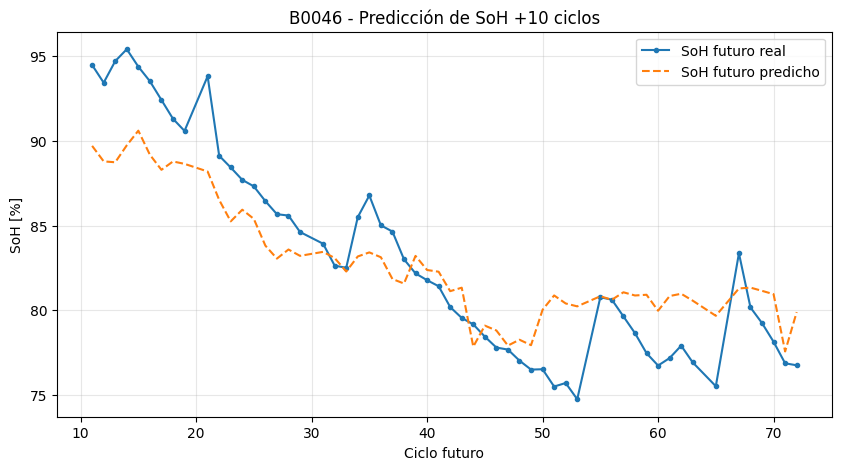

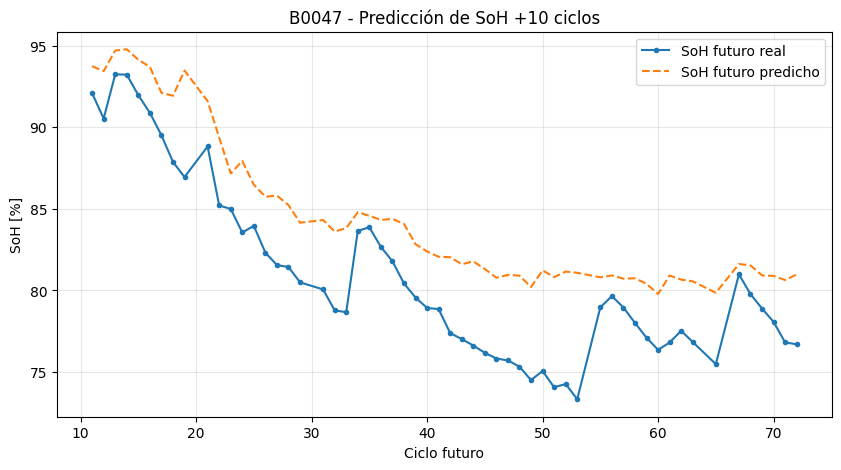

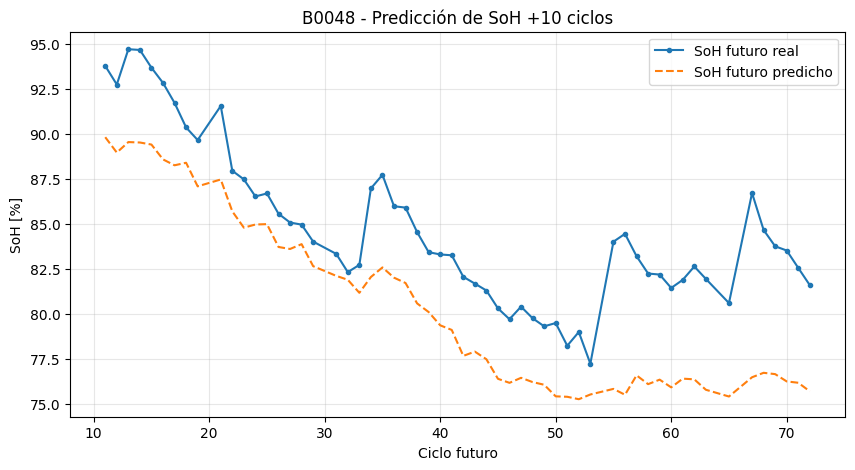

In [39]:
# SoH futuro real vs predicho para cada batería
for battery_id, group in (
    predictions_10
    .groupby("battery_id")
):
    group = group.sort_values(
        "future_cycle"
    )

    plt.figure(figsize=(10, 5))

    plt.plot(
        group["future_cycle"],
        group["soh_future_real"],
        marker=".",
        label="SoH futuro real"
    )

    plt.plot(
        group["future_cycle"],
        group["soh_future_pred"],
        linestyle="--",
        label="SoH futuro predicho"
    )

    plt.xlabel("Ciclo futuro")
    plt.ylabel("SoH [%]")
    plt.title(
        f"{battery_id} - Predicción de SoH +10 ciclos"
    )
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

### Cómo leer las gráficas de futuro

- **Línea real:** lo que realmente ocurrió experimentalmente.
- **Línea predicha:** lo que XGBoost estimó utilizando únicamente información disponible 10 ciclos antes.
- Cuanto más cerca estén las líneas, mejor el pronóstico.
- Si la predicción está sistemáticamente por encima, el modelo **sobreestima la salud futura**.
- Si está sistemáticamente por debajo, la **subestima**.

## 19. Evaluar múltiples horizontes

Ahora repetimos exactamente el mismo procedimiento para:

- +5
- +10
- +20
- +30

Esto permite estudiar cómo cambia la precisión conforme intentamos mirar más lejos hacia el futuro.

In [40]:
metrics_5, predictions_5, models_5 = (
    evaluate_future_xgboost(
        df_clean,
        FEATURES,
        horizon=5
    )
)

metrics_10, predictions_10, models_10 = (
    evaluate_future_xgboost(
        df_clean,
        FEATURES,
        horizon=10
    )
)

metrics_20, predictions_20, models_20 = (
    evaluate_future_xgboost(
        df_clean,
        FEATURES,
        horizon=20
    )
)

metrics_30, predictions_30, models_30 = (
    evaluate_future_xgboost(
        df_clean,
        FEATURES,
        horizon=30
    )
)

print("Horizontes terminados.")

Horizontes terminados.


## 20. Consolidar métricas

Incluimos también `horizon = 0`, que representa el baseline de SoH actual.

In [41]:
all_metrics = pd.concat(
    [
        metrics_0,
        metrics_5,
        metrics_10,
        metrics_20,
        metrics_30
    ],
    ignore_index=True
)

display(
    all_metrics[
        [
            "horizon",
            "test_battery",
            "MAE",
            "RMSE",
            "R2"
        ]
    ].round(4)
)

,horizon,test_battery,MAE,RMSE,R2
0,0,B0045,2.7261,3.6305,0.8522
1,0,B0046,1.4225,1.8713,0.9490
2,0,B0047,3.6210,3.9969,0.7531
3,0,B0048,3.2075,3.4281,0.7293
4,5,B0045,4.7882,5.4758,0.2872
5,5,B0046,2.3757,2.8485,0.8260
6,5,B0047,3.6474,4.1322,0.5816
7,5,B0048,3.7955,4.0206,0.4154
8,10,B0045,3.7181,4.1984,0.4260
9,10,B0046,2.4777,2.9436,0.7607


In [42]:
horizon_summary = (
    all_metrics
    .groupby("horizon")
    .agg(
        MAE_mean=(
            "MAE",
            "mean"
        ),

        MAE_std=(
            "MAE",
            "std"
        ),

        RMSE_mean=(
            "RMSE",
            "mean"
        ),

        RMSE_std=(
            "RMSE",
            "std"
        ),

        R2_mean=(
            "R2",
            "mean"
        ),

        R2_std=(
            "R2",
            "std"
        )
    )
    .reset_index()
)

display(
    horizon_summary.round(4)
)

,horizon,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std
0,0,2.7443,0.9540,3.2317,0.9370,0.8209,0.1006
1,5,3.6517,0.9900,4.1193,1.0747,0.5276,0.2326
2,10,3.5027,0.7382,3.9448,0.7414,0.3707,0.3829
3,20,4.4150,0.9954,4.7666,0.9094,-0.9939,1.0527
4,30,4.0351,1.4421,4.3565,1.3897,-1.9663,1.9917


### Esta tabla es uno de los resultados principales del modelo

Permite comparar:

- estimación actual (`0`)
- predicción a `+5`
- `+10`
- `+20`
- `+30`

La métrica más fácil de explicar ante jurados es **MAE**, porque representa el error promedio en puntos porcentuales de SoH.

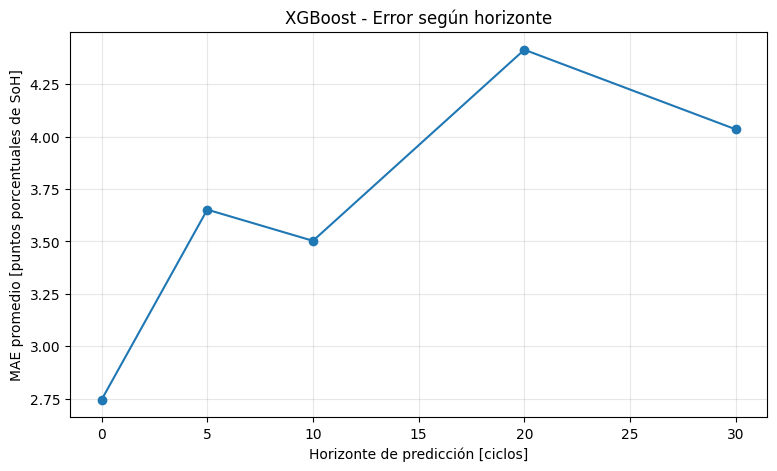

In [43]:
plt.figure(figsize=(9, 5))

plt.plot(
    horizon_summary["horizon"],
    horizon_summary["MAE_mean"],
    marker="o"
)

plt.xlabel("Horizonte de predicción [ciclos]")
plt.ylabel(
    "MAE promedio [puntos porcentuales de SoH]"
)
plt.title(
    "XGBoost - Error según horizonte"
)
plt.grid(alpha=0.3)

plt.savefig(
    os.path.join(
        RESULTS_DIR,
        "MAE_vs_horizonte.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Cómo leer `MAE vs horizonte`

- Eje X: cuántos ciclos hacia el futuro queremos pronosticar.
- Eje Y: cuánto se equivoca el modelo en promedio.
- Más bajo es mejor.
- Si el MAE aumenta con el horizonte, la predicción pierde precisión al mirar más lejos, algo esperable en problemas de forecasting.

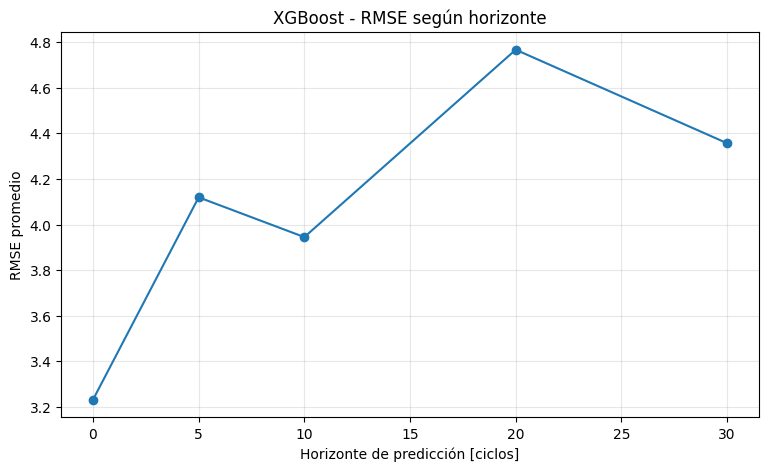

In [44]:
plt.figure(figsize=(9, 5))

plt.plot(
    horizon_summary["horizon"],
    horizon_summary["RMSE_mean"],
    marker="o"
)

plt.xlabel("Horizonte de predicción [ciclos]")
plt.ylabel("RMSE promedio")
plt.title(
    "XGBoost - RMSE según horizonte"
)
plt.grid(alpha=0.3)

plt.savefig(
    os.path.join(
        RESULTS_DIR,
        "RMSE_vs_horizonte.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

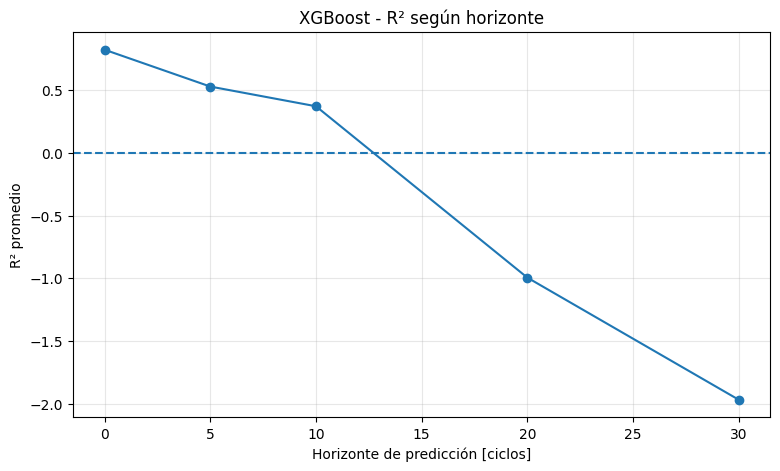

In [45]:
plt.figure(figsize=(9, 5))

plt.plot(
    horizon_summary["horizon"],
    horizon_summary["R2_mean"],
    marker="o"
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Horizonte de predicción [ciclos]")
plt.ylabel("R² promedio")
plt.title(
    "XGBoost - R² según horizonte"
)
plt.grid(alpha=0.3)

plt.savefig(
    os.path.join(
        RESULTS_DIR,
        "R2_vs_horizonte.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 21. Error por batería

Esta gráfica permite detectar si alguna batería es sistemáticamente más difícil de generalizar.

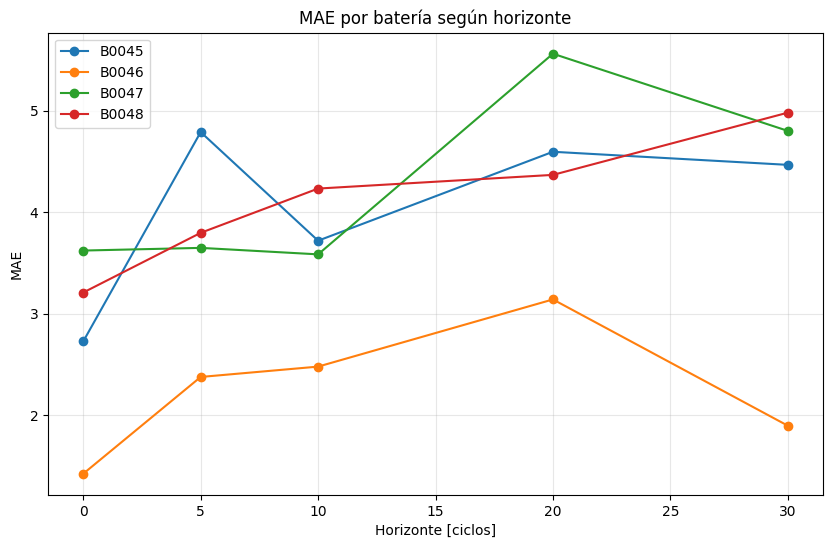

In [46]:
plt.figure(figsize=(10, 6))

for battery_id, group in (
    all_metrics
    .groupby("test_battery")
):
    group = group.sort_values(
        "horizon"
    )

    plt.plot(
        group["horizon"],
        group["MAE"],
        marker="o",
        label=battery_id
    )

plt.xlabel("Horizonte [ciclos]")
plt.ylabel("MAE")
plt.title(
    "MAE por batería según horizonte"
)
plt.legend()
plt.grid(alpha=0.3)

plt.savefig(
    os.path.join(
        RESULTS_DIR,
        "MAE_por_bateria.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 22. Consolidar todas las predicciones futuras

In [47]:
pred_5 = predictions_5.copy()
pred_10 = predictions_10.copy()
pred_20 = predictions_20.copy()
pred_30 = predictions_30.copy()

pred_5["horizon"] = 5
pred_10["horizon"] = 10
pred_20["horizon"] = 20
pred_30["horizon"] = 30

all_future_predictions = pd.concat(
    [
        pred_5,
        pred_10,
        pred_20,
        pred_30
    ],
    ignore_index=True
)

all_future_predictions[
    "error"
] = (
    all_future_predictions[
        "soh_future_pred"
    ]
    -
    all_future_predictions[
        "soh_future_real"
    ]
)

all_future_predictions[
    "absolute_error"
] = np.abs(
    all_future_predictions[
        "error"
    ]
)

display(
    all_future_predictions.head(20)
)

,battery_id,current_cycle,future_cycle,soh_future_real,soh_future_pred,horizon,error,absolute_error
0,B0045,1,6,93.148797,94.425316,5,1.276519,1.276519
1,B0045,2,7,89.652256,92.978714,5,3.326458,3.326458
2,B0045,3,8,92.450691,93.403824,5,0.953133,0.953133
3,B0045,4,9,90.123157,92.498039,5,2.374882,2.374882
4,B0045,5,10,90.305413,91.189903,5,0.884491,0.884491
5,B0045,6,11,87.925482,91.023155,5,3.097674,3.097674
6,B0045,7,12,88.158547,90.796478,5,2.637931,2.637931
7,B0045,8,13,87.134138,91.432655,5,4.298517,4.298517
8,B0045,9,14,89.842381,91.088890,5,1.246509,1.246509
9,B0045,10,15,88.388891,90.766296,5,2.377405,2.377405


## 23. Ver la trayectoria futura predicha de una batería concreta

Este bloque responde directamente:

> Desde un ciclo actual específico, ¿qué SoH predice el modelo a +5, +10, +20 y +30 ciclos?

Los números mostrados serán las predicciones reales obtenidas por los modelos en validación cruzada.

In [48]:
BATTERY = "B0045"
CURRENT_CYCLE = 20

battery_future = (
    all_future_predictions[
        (
            all_future_predictions[
                "battery_id"
            ] == BATTERY
        )
        &
        (
            all_future_predictions[
                "current_cycle"
            ] == CURRENT_CYCLE
        )
    ]
    .sort_values("horizon")
)

display(
    battery_future[
        [
            "battery_id",
            "current_cycle",
            "horizon",
            "future_cycle",
            "soh_future_real",
            "soh_future_pred",
            "absolute_error"
        ]
    ]
)

,battery_id,current_cycle,horizon,future_cycle,soh_future_real,soh_future_pred,absolute_error


### ¿Dónde está la predicción del futuro?

En la columna:

`soh_future_pred`

Ejemplo conceptual:

- ciclo actual: 20
- horizonte: +20
- ciclo futuro: 40
- `soh_future_pred = 84.3`

Interpretación:

> Con la información disponible en el ciclo 20, XGBoost estima que la batería tendrá aproximadamente 84.3 % de SoH en el ciclo 40.

In [49]:
if len(battery_future) > 0:

    plt.figure(figsize=(9, 5))

    plt.plot(
        battery_future[
            "future_cycle"
        ],
        battery_future[
            "soh_future_pred"
        ],
        marker="o",
        label="SoH predicho"
    )

    plt.plot(
        battery_future[
            "future_cycle"
        ],
        battery_future[
            "soh_future_real"
        ],
        marker="o",
        linestyle="--",
        label="SoH real"
    )

    plt.xlabel("Ciclo futuro")
    plt.ylabel("SoH [%]")
    plt.title(
        f"Pronóstico de {BATTERY} "
        f"desde ciclo {CURRENT_CYCLE}"
    )

    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

else:
    print(
        "No hay predicciones disponibles para "
        f"{BATTERY} en el ciclo {CURRENT_CYCLE}."
    )

No hay predicciones disponibles para B0045 en el ciclo 20.


## 24. Importancia de variables de XGBoost

Como cada fold produce un modelo distinto, promediamos la importancia de las variables entre los modelos de validación.

Esto permite analizar si el modelo depende principalmente de:

- número de ciclo
- voltaje
- temperatura
- EIS
- etc.

> La importancia de XGBoost no implica causalidad física. Solo indica cuánto usa el modelo una variable para dividir los datos.

In [50]:
importance_list = []

for test_battery, model in models_10.items():

    fold_importance = pd.DataFrame({
        "feature":
            FEATURES,

        "importance":
            model.feature_importances_,

        "test_battery":
            test_battery
    })

    importance_list.append(
        fold_importance
    )

importance_df = pd.concat(
    importance_list,
    ignore_index=True
)

mean_importance = (
    importance_df
    .groupby("feature")
    ["importance"]
    .mean()
    .sort_values(
        ascending=False
    )
)

display(
    mean_importance.head(15)
)

,importance
feature,
cycle,0.218424
voltage_std,0.198239
cutoff_voltage,0.141619
voltage_min,0.097572
current_std,0.082063
Re_prev,0.044924
Rct_prev,0.040382
voltage_delta,0.032485
voltage_end,0.025786


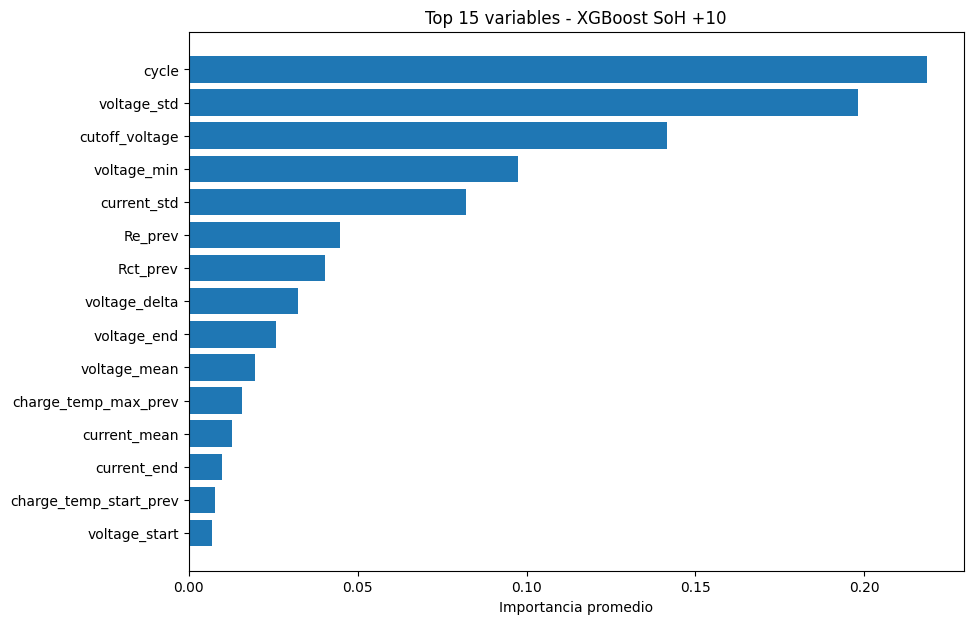

In [51]:
top15 = (
    mean_importance
    .head(15)
    .sort_values()
)

plt.figure(figsize=(10, 7))

plt.barh(
    top15.index,
    top15.values
)

plt.xlabel("Importancia promedio")
plt.title(
    "Top 15 variables - XGBoost SoH +10"
)
plt.show()

## 25. Guardar todos los resultados del experimento

Estos archivos serán los que posteriormente compararemos con GRU y GPR.

In [52]:
# Métricas por batería y horizonte
all_metrics.to_csv(
    os.path.join(
        RESULTS_DIR,
        "metricas_por_bateria.csv"
    ),
    index=False
)

# Resumen por horizonte
horizon_summary.to_csv(
    os.path.join(
        RESULTS_DIR,
        "resumen_por_horizonte.csv"
    ),
    index=False
)

# Todas las predicciones futuras
all_future_predictions.to_csv(
    os.path.join(
        RESULTS_DIR,
        "predicciones_completas.csv"
    ),
    index=False
)

# Importancia promedio +10
mean_importance.to_csv(
    os.path.join(
        RESULTS_DIR,
        "feature_importance_XGBoost_plus10.csv"
    )
)

print("Archivos guardados en:")
print(RESULTS_DIR)

print("\nContenido:")
for item in sorted(
    os.listdir(RESULTS_DIR)
):
    print(" -", item)

Archivos guardados en:
/content/resultados_xgboost

Contenido:
 - B0045_B0048_clean_SoH.csv
 - MAE_por_bateria.png
 - MAE_vs_horizonte.png
 - R2_vs_horizonte.png
 - RMSE_vs_horizonte.png
 - feature_importance_XGBoost_plus10.csv
 - metricas_por_bateria.csv
 - predicciones_completas.csv
 - resumen_por_horizonte.csv


## 26. Resumen automático de resultados

Este bloque identifica cuál horizonte futuro tiene menor MAE y qué batería es más difícil de pronosticar.

In [53]:
future_only_summary = (
    horizon_summary[
        horizon_summary[
            "horizon"
        ] > 0
    ]
    .copy()
)

best_future = (
    future_only_summary
    .loc[
        future_only_summary[
            "MAE_mean"
        ].idxmin()
    ]
)

worst_future = (
    future_only_summary
    .loc[
        future_only_summary[
            "MAE_mean"
        ].idxmax()
    ]
)

battery_summary = (
    all_metrics[
        all_metrics[
            "horizon"
        ] > 0
    ]
    .groupby(
        "test_battery"
    )
    .agg(
        MAE_mean=(
            "MAE",
            "mean"
        ),
        RMSE_mean=(
            "RMSE",
            "mean"
        )
    )
    .reset_index()
)

print(
    "Mejor horizonte futuro por MAE:"
)
print(
    f"+{int(best_future['horizon'])} ciclos"
)
print(
    f"MAE medio = {best_future['MAE_mean']:.4f}"
)

print(
    "\nHorizonte futuro más difícil:"
)
print(
    f"+{int(worst_future['horizon'])} ciclos"
)
print(
    f"MAE medio = {worst_future['MAE_mean']:.4f}"
)

print(
    "\nResumen por batería:"
)
display(
    battery_summary
    .sort_values("MAE_mean")
    .round(4)
)

Mejor horizonte futuro por MAE:
+10 ciclos
MAE medio = 3.5027

Horizonte futuro más difícil:
+20 ciclos
MAE medio = 4.4150

Resumen por batería:


,test_battery,MAE_mean,RMSE_mean
1,B0046,2.4721,2.9101
3,B0048,4.3433,4.6726
0,B0045,4.3914,4.9056
2,B0047,4.3977,4.6989


## 27. Opcional: copiar resultados a Google Drive

`/content` es temporal. Si quieres conservar los resultados entre sesiones, ejecuta esta sección.

In [54]:
# OPCIONAL
#
# from google.colab import drive
# drive.mount("/content/drive")
#
# DRIVE_RESULTS_DIR = (
#     "/content/drive/MyDrive/"
#     "Proyecto_Grado_Baterias/"
#     "results/xgboost"
# )
#
# os.makedirs(
#     DRIVE_RESULTS_DIR,
#     exist_ok=True
# )
#
# import shutil
#
# for item in os.listdir(RESULTS_DIR):
#     source = os.path.join(
#         RESULTS_DIR,
#         item
#     )
#
#     destination = os.path.join(
#         DRIVE_RESULTS_DIR,
#         item
#     )
#
#     if os.path.isfile(source):
#         shutil.copy2(
#             source,
#             destination
#         )
#
# print(
#     "Resultados copiados a:",
#     DRIVE_RESULTS_DIR
# )

# 28. Qué resultados debes presentar ante el jurado

## Resultado 1 — Calidad de estimación actual

Tabla `metrics_0`:

- MAE
- RMSE
- R²

demuestra si el modelo puede reconocer el estado actual de una batería desconocida.

## Resultado 2 — Predicción futura

Tabla `horizon_summary`:

- +5
- +10
- +20
- +30 ciclos

muestra cómo cambia la precisión cuando el horizonte aumenta.

## Resultado 3 — Futuro de una batería concreta

Tabla `battery_future`:

La columna **`soh_future_pred`** es la predicción de SoH futuro.

## Resultado 4 — Gráfica real vs predicho

Permite evaluar visualmente si la tendencia estimada sigue la degradación realmente observada.

## Resultado 5 — MAE vs horizonte

Muestra cuánto aumenta o disminuye el error cuando intentamos mirar más lejos hacia el futuro.

## Resultado 6 — Rendimiento por batería

Permite detectar si el modelo generaliza peor en una batería específica.

---

# 29. Qué NO debemos afirmar todavía

Todavía no debemos afirmar que:

- este es el modelo definitivo;
- XGBoost es mejor que GRU o GPR;
- tenemos una RUL validada;
- el umbral de EOL ya está definido para todo el proyecto.

Para eso todavía debemos:

1. ampliar el dataset;
2. comparar con GRU;
3. comparar con GPR;
4. definir formalmente EOL;
5. construir y validar RUL;
6. estudiar baterías censuradas;
7. realizar análisis de sensibilidad y ablation.

# 30. Próxima fase del proyecto

Con este notebook queda reproducible el primer modelo XGBoost de SoH actual y futuro.

La siguiente fase puede construirse sobre los mismos datos procesados:

### RUL

\[
X_t
ightarrow RUL_t
\]

### GRU

Modelo recurrente que utilizará ventanas temporales de varios ciclos.

### GPR

Modelo probabilístico que permitirá obtener predicción e incertidumbre.

Finalmente construiremos una tabla común:

| Modelo | Horizonte | MAE | RMSE | R² |
|---|---:|---:|---:|---:|
| XGBoost | +5 | ... | ... | ... |
| XGBoost | +10 | ... | ... | ... |
| GRU | +5 | ... | ... | ... |
| GPR | +5 | ... | ... | ... |

y compararemos los modelos **sobre baterías completamente no vistas**.

In [55]:
print(
    "df_clean:",
    "df_clean" in globals()
)

print(
    "FEATURES:",
    "FEATURES" in globals()
)

print(
    "create_future_dataset:",
    "create_future_dataset" in globals()
)

df_clean: True
FEATURES: True
create_future_dataset: True


# Modelos finales para producción

Los modelos utilizados durante Leave-One-Battery-Out tenían como objetivo
evaluar generalización.

Para desplegar el sistema se entrenan nuevos modelos utilizando todas las
baterías piloto disponibles.

Se genera un modelo independiente para:

- SoH actual
- SoH +5 ciclos
- SoH +10 ciclos
- SoH +20 ciclos
- SoH +30 ciclos

In [56]:
from pathlib import Path
import json

import xgboost
import sklearn


PRODUCTION_DIR = Path(
    "/content/xgboost_production"
)

PRODUCTION_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print(PRODUCTION_DIR)

/content/xgboost_production


In [57]:
def create_xgboost_model():
    return XGBRegressor(
        n_estimators=500,
        learning_rate=0.03,
        max_depth=4,
        min_child_weight=3,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.0,
        reg_lambda=1.0,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1,
    )

In [58]:
X_current = (
    df_clean[
        FEATURES
    ]
    .copy()
)

y_current = (
    df_clean[
        "soh"
    ]
    .copy()
)

model_0 = (
    create_xgboost_model()
)

model_0.fit(
    X_current,
    y_current
)

print(
    "Modelo SoH actual entrenado."
)

print(
    "Observaciones:",
    len(X_current)
)

Modelo SoH actual entrenado.
Observaciones: 277


In [59]:
production_models = {
    0: model_0
}

training_rows = {
    0: len(X_current)
}


for horizon in [
    5,
    10,
    20,
    30
]:

    future_df, target_name = (
        create_future_dataset(
            df_clean,
            horizon
        )
    )

    X_h = (
        future_df[
            FEATURES
        ]
        .copy()
    )

    y_h = (
        future_df[
            target_name
        ]
        .copy()
    )

    model = (
        create_xgboost_model()
    )

    model.fit(
        X_h,
        y_h
    )

    production_models[
        horizon
    ] = model

    training_rows[
        horizon
    ] = len(
        X_h
    )

    print(
        f"Modelo +{horizon} ciclos "
        f"entrenado con {len(X_h)} filas."
    )

Modelo +5 ciclos entrenado con 246 filas.
Modelo +10 ciclos entrenado con 230 filas.
Modelo +20 ciclos entrenado con 197 filas.
Modelo +30 ciclos entrenado con 157 filas.


In [60]:
for horizon, model in (
    production_models.items()
):

    if horizon == 0:

        filename = (
            "xgboost_soh_current.json"
        )

    else:

        filename = (
            f"xgboost_soh_plus_{horizon}.json"
        )

    output_path = (
        PRODUCTION_DIR
        /
        filename
    )

    model.save_model(
        output_path
    )

    print(
        "Guardado:",
        output_path
    )

Guardado: /content/xgboost_production/xgboost_soh_current.json
Guardado: /content/xgboost_production/xgboost_soh_plus_5.json
Guardado: /content/xgboost_production/xgboost_soh_plus_10.json
Guardado: /content/xgboost_production/xgboost_soh_plus_20.json
Guardado: /content/xgboost_production/xgboost_soh_plus_30.json


In [61]:
features_path = (
    PRODUCTION_DIR
    /
    "features.json"
)

with open(
    features_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        FEATURES,
        file,
        indent=2,
        ensure_ascii=False
    )

print(
    features_path
)

/content/xgboost_production/features.json


In [62]:
metadata = {

    "model_family":
        "XGBoost",

    "task":
        "State of Health prediction",

    "target":
        "SoH_percent",

    "window_seconds":
        300,

    "horizons_cycles":
        [
            0,
            5,
            10,
            20,
            30
        ],

    "training_batteries":
        [
            "B0045",
            "B0046",
            "B0047",
            "B0048"
        ],

    "number_of_features":
        len(
            FEATURES
        ),

    "training_rows":
        training_rows,

    "soh_definition":
        (
            "capacity / median(first 5 valid capacities) * 100"
        ),

    "xgboost_version":
        xgboost.__version__,

    "sklearn_version":
        sklearn.__version__,

    "notes": {
        "plus_5":
            "validated pilot horizon",

        "plus_10":
            "validated pilot horizon",

        "plus_20":
            (
                "experimental: pilot validation "
                "showed weak long-horizon generalization"
            ),

        "plus_30":
            (
                "experimental: pilot validation "
                "showed weak long-horizon generalization"
            )
    }
}

In [63]:
metadata_path = (
    PRODUCTION_DIR
    /
    "metadata.json"
)

with open(
    metadata_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        metadata,
        file,
        indent=2,
        ensure_ascii=False
    )

print(
    metadata_path
)

/content/xgboost_production/metadata.json


In [64]:
manifest = {

    "current": {
        "horizon": 0,
        "file":
            "xgboost_soh_current.json"
    },

    "plus_5": {
        "horizon": 5,
        "file":
            "xgboost_soh_plus_5.json"
    },

    "plus_10": {
        "horizon": 10,
        "file":
            "xgboost_soh_plus_10.json"
    },

    "plus_20": {
        "horizon": 20,
        "file":
            "xgboost_soh_plus_20.json"
    },

    "plus_30": {
        "horizon": 30,
        "file":
            "xgboost_soh_plus_30.json"
    }
}

In [65]:
with open(
    PRODUCTION_DIR
    /
    "manifest.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        manifest,
        file,
        indent=2
    )

In [66]:
for path in sorted(
    PRODUCTION_DIR.iterdir()
):

    print(
        path.name
    )

features.json
manifest.json
metadata.json
xgboost_soh_current.json
xgboost_soh_plus_10.json
xgboost_soh_plus_20.json
xgboost_soh_plus_30.json
xgboost_soh_plus_5.json


In [67]:
test_model = (
    XGBRegressor()
)

test_model.load_model(
    PRODUCTION_DIR
    /
    "xgboost_soh_plus_10.json"
)

In [68]:
test_prediction = (
    test_model.predict(
        X_current[
            FEATURES
        ].iloc[
            [0]
        ]
    )
)

print(
    "Predicción de prueba:",
    test_prediction
)

Predicción de prueba: [87.93348]


In [69]:
with open(
    PRODUCTION_DIR
    /
    "features.json",
    encoding="utf-8"
) as file:

    stored_features = (
        json.load(
            file
        )
    )


print(
    "Features Colab:",
    len(
        FEATURES
    )
)

print(
    "Features exportadas:",
    len(
        stored_features
    )
)

print(
    "Orden idéntico:",
    FEATURES
    ==
    stored_features
)

Features Colab: 29
Features exportadas: 29
Orden idéntico: True


In [70]:
import shutil


zip_path = shutil.make_archive(
    "/content/xgboost_production",
    "zip",
    PRODUCTION_DIR
)

print(
    zip_path
)

/content/xgboost_production.zip


In [71]:
from google.colab import files

files.download(
    "/content/xgboost_production.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [72]:
import os

print(
    os.path.exists(
        "/content/xgboost_production.zip"
    )
)

True


In [73]:
from pathlib import Path
import json
import numpy as np
import pandas as pd


DOMAIN_PROFILE_PATH = Path(
    "/content/domain_profile.json"
)


domain_profile = {
    "schema_version": 1,
    "description": (
        "Distribución de las features utilizadas "
        "para entrenar el modelo XGBoost."
    ),
    "training_rows": int(len(df_clean)),
    "training_batteries": sorted(
        df_clean[
            "battery_id"
        ]
        .astype(str)
        .unique()
        .tolist()
    ),
    "feature_order": FEATURES,
    "ranges": {},
}


for feature in FEATURES:

    values = pd.to_numeric(
        df_clean[feature],
        errors="coerce",
    )

    values = values.replace(
        [
            np.inf,
            -np.inf,
        ],
        np.nan,
    ).dropna()


    if len(values) == 0:

        domain_profile[
            "ranges"
        ][feature] = {
            "count": 0,
            "min": None,
            "p05": None,
            "median": None,
            "p95": None,
            "max": None,
        }

        continue


    domain_profile[
        "ranges"
    ][feature] = {

        "count":
            int(
                len(values)
            ),

        "min":
            float(
                values.min()
            ),

        "p05":
            float(
                values.quantile(
                    0.05
                )
            ),

        "median":
            float(
                values.median()
            ),

        "p95":
            float(
                values.quantile(
                    0.95
                )
            ),

        "max":
            float(
                values.max()
            ),
    }


with open(
    DOMAIN_PROFILE_PATH,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        domain_profile,
        file,
        indent=2,
        ensure_ascii=False,
    )


print(
    "Archivo creado:",
    DOMAIN_PROFILE_PATH
)

print(
    "Features:",
    len(
        domain_profile[
            "ranges"
        ]
    )
)

print(
    "Baterías:",
    domain_profile[
        "training_batteries"
    ]
)


Archivo creado: /content/domain_profile.json
Features: 29
Baterías: ['B0045', 'B0046', 'B0047', 'B0048']


In [74]:
from google.colab import files

files.download(
    "/content/domain_profile.json"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>